In [28]:
import sys

# Caminho do pacote neste computador.
sys.path.insert(
    0,
    "/home/paulo-vinicius/Documentos/Ciência de Dados/"
    "Machine_Learning/regressao_modelos_lineares/"
    "04_regressao_polinomial/src",
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, ValidationCurveDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

from polinomial.auxiliares import dataframe_coeficientes
from polinomial.config import DADOS_EXEMPLO_POLINOMIAL
from polinomial.graficos import plot_coeficientes, plot_residuos
from polinomial.modelos import grid_search_cv_regressor

sns.set_theme(palette="bright")

RANDOM_STATE = 1

In [29]:
df = pd.read_csv(DADOS_EXEMPLO_POLINOMIAL)

df.head()

,X,y
0,0.261961,7.620010
1,0.903381,8.254397
2,0.020782,2.712432
3,0.899936,8.855505
4,0.097239,5.699531


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       100 non-null    float64
 1   y       100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


In [31]:
X = df[["X"]]
y = df["y"]

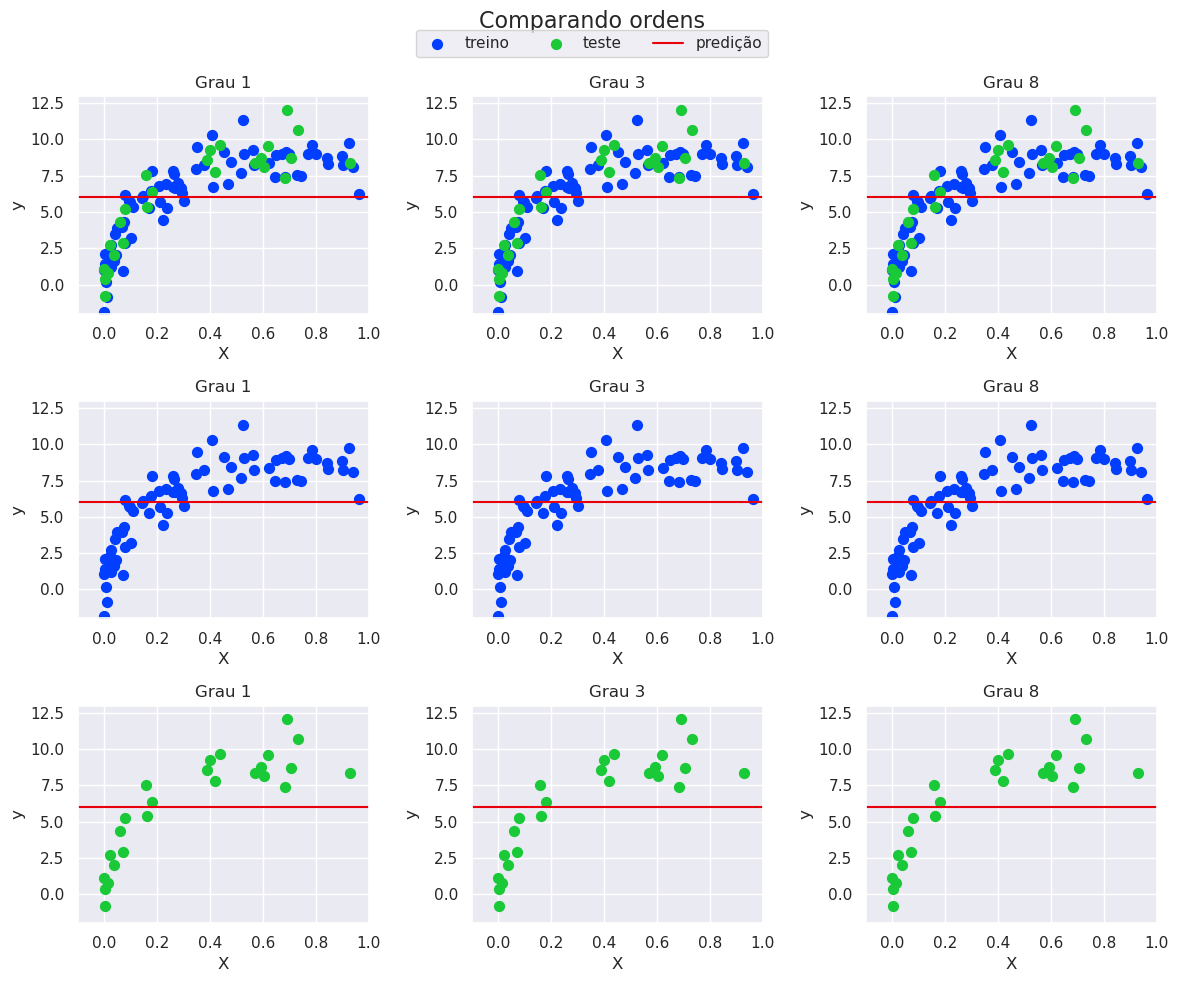

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

xfit = np.linspace(-0.1, 1.1, 1000)
df_xfit = pd.DataFrame({"X": xfit})

ordens = (1, 3, 8)
titulos = ("Grau 1", "Grau 3", "Grau 8")
parametros_modelos = {}
regressor = Lasso()

fig, axes = plt.subplots(3, 3, figsize=(12, 10), tight_layout=True)

for ordem, titulo, ax in zip(ordens, titulos, axes.flatten()[:3]):
    model = Pipeline([("poly", PolynomialFeatures(ordem, include_bias=False)), ("reg", regressor)])
    model.fit(X_train, y_train)
    y_pred = model.predict(df_xfit)

    parametros_modelos[titulo] = {
        "modelo": model,
        "coef": model.named_steps["reg"].coef_,
        "intercept": model.named_steps["reg"].intercept_,
    }

    ax.scatter(X_train, y_train, s=50, color="C0", label="treino")
    ax.scatter(X_test, y_test, s=50, color="C2", label="teste")

    ax.plot(xfit, y_pred, color="C3", label="predição")

    ax.set_title(titulo)
    ax.set_xlim(-0.1, 1.0)
    ax.set_ylim(-2, 13)
    ax.set_xlabel("X")
    ax.set_ylabel("y")

    handles, labels = ax.get_legend_handles_labels()

for ordem, titulo, ax in zip(ordens, titulos, axes.flatten()[3:6]):
    model = Pipeline([("poly", PolynomialFeatures(ordem, include_bias=False)), ("reg", regressor)])
    model.fit(X_train, y_train)
    y_pred = model.predict(df_xfit)

    ax.scatter(X_train, y_train, s=50, color="C0", label="treino")

    ax.plot(xfit, y_pred, color="C3", label="predição")

    ax.set_title(titulo)
    ax.set_xlim(-0.1, 1.0)
    ax.set_ylim(-2, 13)
    ax.set_xlabel("X")
    ax.set_ylabel("y")

for ordem, titulo, ax in zip(ordens, titulos, axes.flatten()[6:]):
    model = Pipeline([("poly", PolynomialFeatures(ordem, include_bias=False)), ("reg", regressor)])
    model.fit(X_train, y_train)
    y_pred = model.predict(df_xfit)

    ax.scatter(X_test, y_test, s=50, color="C2", label="teste")

    ax.plot(xfit, y_pred, color="C3", label="predição")

    ax.set_title(titulo)
    ax.set_xlim(-0.1, 1.0)
    ax.set_ylim(-2, 13)
    ax.set_xlabel("X")
    ax.set_ylabel("y")


fig.suptitle(f"Comparando ordens\n", fontsize=16)
fig.legend(
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.925),
    bbox_transform=fig.transFigure,
    handles=handles,
    labels=labels,
)


plt.show()

In [33]:
parametros_modelos

{'Grau 1': {'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=1, include_bias=False)),
                  ('reg', Lasso())]),
  'coef': array([0.]),
  'intercept': 6.011644354078621},
 'Grau 3': {'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=3, include_bias=False)),
                  ('reg', Lasso())]),
  'coef': array([0., 0., 0.]),
  'intercept': 6.011644354078621},
 'Grau 8': {'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=8, include_bias=False)),
                  ('reg', Lasso())]),
  'coef': array([0., 0., 0., 0., 0., 0., 0., 0.]),
  'intercept': 6.011644354078621}}

In [34]:
parametros_modelos["Grau 1"]

{'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=1, include_bias=False)),
                 ('reg', Lasso())]),
 'coef': array([0.]),
 'intercept': 6.011644354078621}

In [35]:
parametros_modelos["Grau 3"]

{'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=3, include_bias=False)),
                 ('reg', Lasso())]),
 'coef': array([0., 0., 0.]),
 'intercept': 6.011644354078621}

In [36]:
parametros_modelos["Grau 8"]

{'modelo': Pipeline(steps=[('poly', PolynomialFeatures(degree=8, include_bias=False)),
                 ('reg', Lasso())]),
 'coef': array([0., 0., 0., 0., 0., 0., 0., 0.]),
 'intercept': 6.011644354078621}

In [37]:
X.head()

,X
0,0.261961
1,0.903381
2,0.020782
3,0.899936
4,0.097239


In [38]:
parametros_modelos["Grau 1"]["modelo"]

Pipeline(steps=[('poly', PolynomialFeatures(degree=1, include_bias=False)),
                ('reg', Lasso())])

In [39]:
parametros_modelos["Grau 1"]["modelo"]["poly"].transform(X)[:5]

array([[0.26196138],
       [0.90338124],
       [0.02078199],
       [0.89993577],
       [0.09723885]])

In [40]:
parametros_modelos["Grau 3"]["modelo"]["poly"].transform(X)[:5]

array([[2.61961376e-01, 6.86237623e-02, 1.79767752e-02],
       [9.03381238e-01, 8.16097661e-01, 7.37247316e-01],
       [2.07819939e-02, 4.31891272e-04, 8.97556180e-06],
       [8.99935774e-01, 8.09884397e-01, 7.28843941e-01],
       [9.72388545e-02, 9.45539482e-03, 9.19431761e-04]])

In [41]:
parametros_modelos["Grau 8"]["modelo"]["poly"].transform(X)[:5]

array([[2.61961376e-01, 6.86237623e-02, 1.79767752e-02, 4.70922075e-03,
        1.23363394e-03, 3.23164445e-04, 8.46566025e-05, 2.21767600e-05],
       [9.03381238e-01, 8.16097661e-01, 7.37247316e-01, 6.66015393e-01,
        6.01665810e-01, 5.43533604e-01, 4.91018060e-01, 4.43576503e-01],
       [2.07819939e-02, 4.31891272e-04, 8.97556180e-06, 1.86530071e-07,
        3.87646680e-09, 8.05607096e-11, 1.67421218e-12, 3.47934674e-14],
       [8.99935774e-01, 8.09884397e-01, 7.28843941e-01, 6.55912736e-01,
        5.90279335e-01, 5.31213490e-01, 4.78058023e-01, 4.30221517e-01],
       [9.72388545e-02, 9.45539482e-03, 9.19431761e-04, 8.94044912e-05,
        8.69359030e-06, 8.45354762e-07, 8.22013287e-08, 7.99316304e-09]])

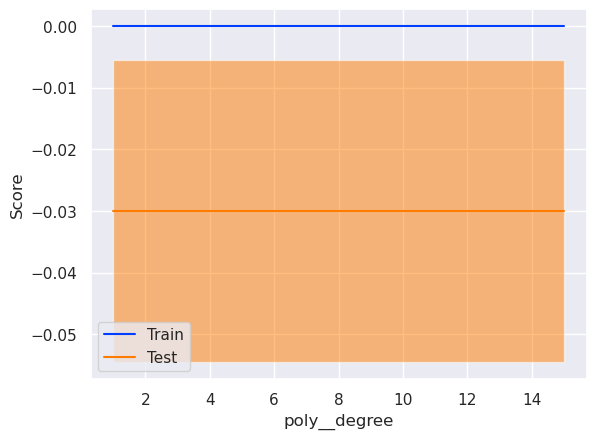

In [42]:
ValidationCurveDisplay.from_estimator(
    parametros_modelos["Grau 1"]["modelo"],
    X,
    y,
    param_name="poly__degree",
    param_range=np.arange(1, 16),
)

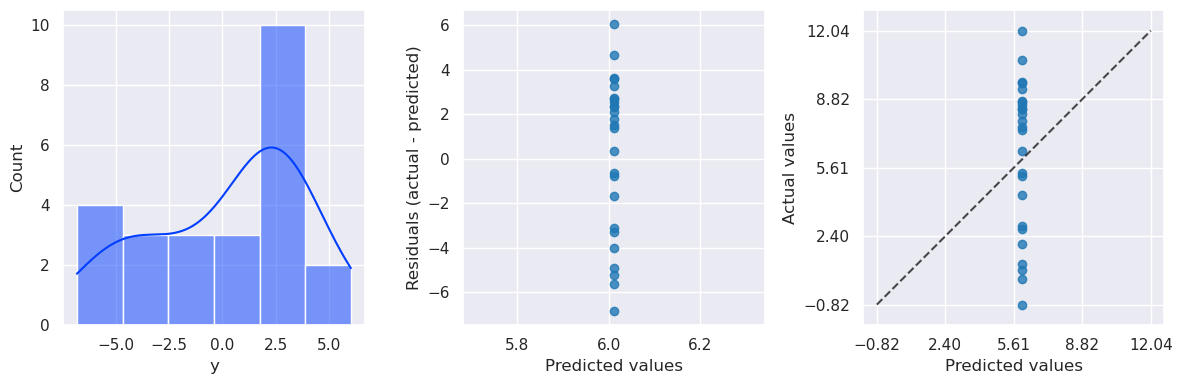

In [43]:
model = Pipeline(
    [
        ("poly", PolynomialFeatures(3, include_bias=False)),
        ("reg", regressor)
    ]
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

plot_residuos(y_test, y_pred)

In [44]:
preprocessamento = PolynomialFeatures(include_bias=False)

param_grid = {
    "preprocessor__degree": np.arange(1, 16), 
    "reg__alpha": [1E-2, 5E-2, 1E-1, 5E-1, 1, 5, 10]

}

grid_search = grid_search_cv_regressor(regressor=regressor, preprocessor=preprocessamento, param_grid=param_grid)

grid_search

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        PolynomialFeatures(include_bias=False)),
                                       ('reg', Lasso())]),
             n_jobs=-1,
             param_grid={'preprocessor__degree': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15]),
                         'reg__alpha': [0.01, 0.05, 0.1, 0.5, 1, 5, 10]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [45]:
grid_search.fit(X, y)

Fitting 5 folds for each of 105 candidates, totalling 525 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        PolynomialFeatures(include_bias=False)),
                                       ('reg', Lasso())]),
             n_jobs=-1,
             param_grid={'preprocessor__degree': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15]),
                         'reg__alpha': [0.01, 0.05, 0.1, 0.5, 1, 5, 10]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [46]:
grid_search.best_score_

-1.3004430267050524

In [47]:
grid_search.best_estimator_["reg"].coef_

array([ 21.98831163, -16.50523784])

In [48]:
grid_search.best_estimator_["reg"].intercept_

1.8713572789939166

In [49]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()

array(['X', 'X^2'], dtype=object)

In [50]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_["reg"].coef_,
    grid_search.best_estimator_["preprocessor"].get_feature_names_out()
)

coefs

,coeficiente
X^2,-16.505238
X,21.988312


In [51]:
grid_search.best_params_

{'preprocessor__degree': 2, 'reg__alpha': 0.01}

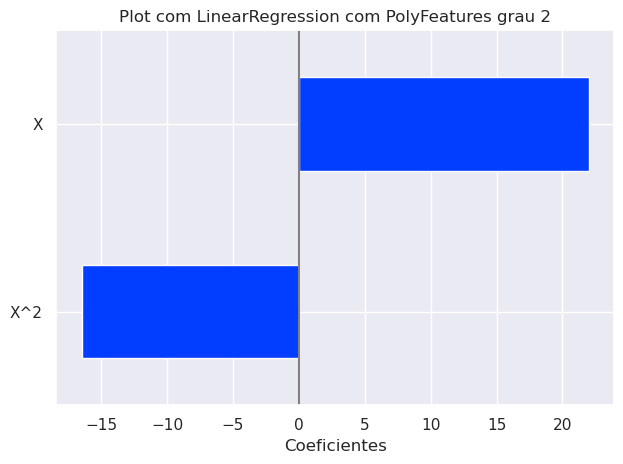

In [52]:
grau = grid_search.best_params_["preprocessor__degree"]

plot_coeficientes(coefs, f"Plot com LinearRegression com PolyFeatures grau {grau}")

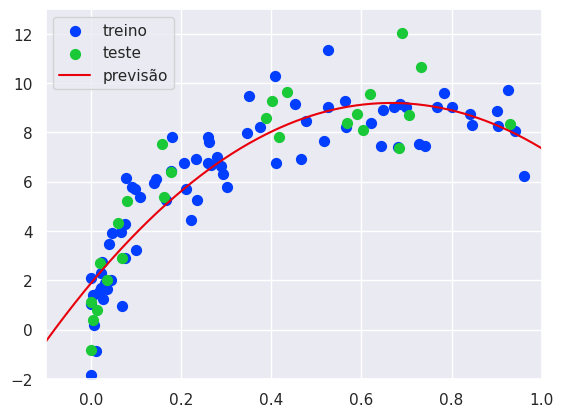

In [53]:
fig, ax = plt.subplots()

y_pred = grid_search.best_estimator_.predict(df_xfit)

ax.scatter(X_train, y_train, s=50, color="C0", label="treino")
ax.scatter(X_test,y_test, s=50, color="C2", label="teste")

ax.plot(xfit, y_pred, color="C3", label="previsão")

ax.set_xlim(-0.1, 1.0)
ax.set_ylim(-2, 13)

ax.legend()
plt.show()